# Writer-Adaptive Cohort-Margin Calibration for One-Class Signature Verification
### Experiment v7 — necessity test, competing baselines, development partition

This experiment tests whether per-writer calibration of a one-class support vector
machine is **necessary**, rather than merely effective. Three claims that previous
versions asserted without evidence are put to a test that can fail.

### What v6 established, and what it left open

Calibration lowers false rejection significantly in every arm tested, and that is
not in question. Three things were asserted without support.

**The necessity claim was untested.** The fixed baseline in v6 was a single point,
ν = 0.10 with the `scale` heuristic. Nothing swept a range of global settings, so
the claim that no single global pair reaches the calibrated operating points rested
on one comparison. Section 5 sweeps the full global grid and plots its frontier
against the calibrated points. If a global pair reaches the same place, the claim
fails and the contribution is a convenience rather than a capability.

**A simpler competitor was never run.** Refitting the boundary per writer is only
one way to adapt. Setting a per-writer *threshold* on the decision score — at a
quantile of that writer's leave-one-out scores, using no forged sample — adapts the
operating point without touching ν or γ at all. Section 6 runs it. If it matches
calibration, calibration adds nothing beyond it.

**The trivial control was handicapped.** In v6 the nine image statistics passed
through the same 17-dimensional descriptor as the 4,356-dimensional HOG vector, and
`N_BANDS = 8` applied to a nine-element vector left seven descriptor dimensions
identically zero while the eighth could only take ±1. The control therefore ran on
roughly nine usable dimensions and still produced the best-performing arm
(AUC 0.9961 calibrated, balanced accuracy 0.9358). It is given a descriptor suited
to its dimensionality here, and a single-statistic control is added alongside it.

### Further corrections

**Matched false acceptance is computed per writer.** v6 applied one additive offset
to scores pooled across writers whose γ differed by up to 6,792×, which is not a
valid comparison; it produced values such as a false rejection rate of 0.9567. Each
writer is now matched to their own baseline rate.

**Kernel degeneracy is measured.** Grid self-extension reached three steps, placing
γ up to 1,000× below the base grid. A near-constant kernel is how v1 and v2 produced
apparent gains that were not real, so the kernel value at a typical enrolled pair is
now reported per writer and flagged above 0.99. The solver tolerance is tightened
from the default 1e-3 to 1e-10, which mattered for order-dependence at small γ.

**The cohort is made selective.** Twenty surrogate impostors drawn from twenty-four
available writers excluded only four, so the cohort was not hard in any meaningful
sense; mean cohort acceptance of 0.01 to 0.08 meant the margin criterion reduced to
maximising leave-one-out acceptance. The cohort is reduced to the five nearest
writers.

**Multiplicity and interval estimates.** Roughly ninety uncorrected tests were
reported in v6. The primary family is corrected by the Holm step-down procedure, and
margins against the control carry bootstrap confidence intervals over writers.

### Hypotheses

Two-tailed paired Wilcoxon signed-rank tests across development writers, Holm-corrected
within the primary family, α = 0.05.

- H₀: per-writer calibration produces no difference in median FRR relative to the
  best available global hyperparameter setting.
- H₁: per-writer calibration produces a difference in median FRR.

The comparator is the **best** global setting found by the Section 5 sweep, not a
single pre-chosen point. This is a harder null than v6 tested and it is the one the
necessity claim requires.

### Partition

Twenty-five development writers; thirty confirmation writers, not read here.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import numpy as np, pandas as pd, itertools, random, time, sys, platform
from PIL import Image, ImageOps
from math import floor, ceil, sqrt
from skimage.feature import hog
from skimage.filters import threshold_otsu
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr, wilcoxon
import matplotlib.pyplot as plt
from pathlib import Path

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED); random.seed(RANDOM_SEED)

NB_T0 = time.time(); SECTION_TIMES = {}
def mark(section):
    now = time.time(); prev = SECTION_TIMES.get("_last", NB_T0)
    SECTION_TIMES[section] = now - prev; SECTION_TIMES["_last"] = now
    print(f"[timer] {section}: {now-prev:.1f}s   (total {now-NB_T0:.1f}s)", flush=True)

_trapz = getattr(np, "trapezoid", None) or np.trapz   # np.trapz removed in NumPy 2

print(f"Python {sys.version.split()[0]} | {platform.machine()} | numpy {np.__version__}")
print("Estimator: sklearn OneClassSVM (CPU-only)")

Python 3.13.16 | x86_64 | numpy 2.1.3
Estimator: sklearn OneClassSVM (CPU-only)


In [ ]:
DATASET_DIR = Path("/content/drive/MyDrive/cedar-dataset/signatures")
GENUINE_DIR = DATASET_DIR/"full_org"; FORGED_DIR = DATASET_DIR/"full_forg"
CACHE_DIR = Path("/content/drive/MyDrive/4buwan_cache"); CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("/content/drive/MyDrive/4buwan_results_v7"); OUT_DIR.mkdir(parents=True, exist_ok=True)
USE_CACHE = True

IMG_SIZE = (100,100); MAX_CROP_ASPECT = 2.5; DENSITY_FRAC = 0.05
N_WRITERS = 55; N_TRAIN_GENUINE = 12
INK_THRESH = 0.2
SPLIT_SEED = 20261014; N_DEV = 25

HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8,8), cells_per_block=(2,2), block_norm="L2-Hys")
N_BANDS = 8

# ---- v7: solver tolerance. sklearn's default 1e-3 gave order-dependent results at small gamma ----
SVM_TOL = 1e-10

PAIR_BASELINE = {"nu": 0.10, "gamma": "scale"}

NU_GRID = (0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30)
GAMMA_MULTIPLIERS = (0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0)
MAX_GRID_EXTENSIONS = 4; GRID_EXTEND_FACTOR = 10.0
TARGET_ACCEPT = 0.70; TARGET_COHORT_REJECT = 0.95

# ---- v7: a genuinely hard cohort. 20 of 24 excluded only 4 writers ----
COHORT_SIZE = 5
HARD_COHORT = True

# ---- v7: the global frontier. absolute gamma, identical for every writer ----
GLOBAL_NU_GRID = (0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.45)
GLOBAL_GAMMA_GRID = tuple(10.0**k for k in range(-5, 3))   # 1e-5 .. 1e2
# ---- v7: the per-writer threshold competitor ----
THRESHOLD_QUANTILES = (0.05, 0.10, 0.20, 0.30)

KERNEL_DEGENERATE_AT = 0.99
BOOTSTRAP_N = 2000

CONDITIONS = ("gray", "bin")
REPS = ("RAW", "HOG", "GEO", "FD")     # GEO = nine statistics, FD = fill_density alone
CONTROL_REPS = ("GEO", "FD")
PRIMARY = ("HOG", "bin")               # pre-declared, unchanged from v6

print("Configuration set.")
print(f"  solver tol        : {SVM_TOL} (was sklearn default 1e-3)")
print(f"  cohort size       : {COHORT_SIZE} of {N_DEV-1} available (was 20)")
print(f"  global frontier   : {len(GLOBAL_NU_GRID)} nu x {len(GLOBAL_GAMMA_GRID)} absolute gamma "
      f"= {len(GLOBAL_NU_GRID)*len(GLOBAL_GAMMA_GRID)} settings")
print(f"  threshold rule    : quantiles {THRESHOLD_QUANTILES} of per-writer LOO scores")
print(f"  primary arm       : {PRIMARY[0]}-{PRIMARY[1]} (pre-declared)")

Configuration set.
  solver tol        : 1e-10 (was sklearn default 1e-3)
  cohort size       : 5 of 24 available (was 20)
  global frontier   : 8 nu x 8 absolute gamma = 64 settings
  threshold rule    : quantiles (0.05, 0.1, 0.2, 0.3) of per-writer LOO scores
  primary arm       : HOG-bin (pre-declared)


In [4]:
genuine_files = sorted(GENUINE_DIR.glob("*.png")); forged_files = sorted(FORGED_DIR.glob("*.png"))
def get_writer_id(fp): return int(Path(fp).stem.split("_")[1])
assert len(genuine_files)==1320 and len(forged_files)==1320

rng_split = random.Random(RANDOM_SEED); writer_splits = {}
for wid in range(1, N_WRITERS+1):
    g = sorted([p for p in genuine_files if get_writer_id(p)==wid])
    f = sorted([p for p in forged_files  if get_writer_id(p)==wid])
    sg = g.copy(); rng_split.shuffle(sg); sf = f.copy(); rng_split.shuffle(sf)
    writer_splits[wid] = {"train_genuine": sg[:N_TRAIN_GENUINE],
                          "test_genuine":  sg[N_TRAIN_GENUINE:], "test_forged": sf}

_perm = np.random.default_rng(SPLIT_SEED).permutation(np.arange(1, N_WRITERS+1))
DEV = sorted(int(w) for w in _perm[:N_DEV]); CONFIRM = sorted(int(w) for w in _perm[N_DEV:])
assert DEV == [3,8,9,10,12,17,19,21,22,23,28,29,34,36,39,40,42,43,44,47,49,50,51,52,55]

SPLIT_KEYS = [("train","train_genuine"), ("test_gen","test_genuine"), ("test_for","test_forged")]
FILES = {k: [p for w in range(1, N_WRITERS+1) for p in writer_splits[w][src]] for k, src in SPLIT_KEYS}
def _rows(key, writers):
    s = set(writers); return np.array([i for i,p in enumerate(FILES[key]) if get_writer_id(p) in s], int)

print(f"Development  ({len(DEV)}): {DEV}")
print(f"Confirmation ({len(CONFIRM)}): held in reserve, not evaluated in this notebook")
print(f"Per writer: {N_TRAIN_GENUINE} enrolled genuine, "
      f"{24-N_TRAIN_GENUINE} held-out genuine, 24 forged")
mark("1 partition")

Development  (25): [3, 8, 9, 10, 12, 17, 19, 21, 22, 23, 28, 29, 34, 36, 39, 40, 42, 43, 44, 47, 49, 50, 51, 52, 55]
Confirmation (30): held in reserve, not evaluated in this notebook
Per writer: 12 enrolled genuine, 12 held-out genuine, 24 forged
[timer] 1 partition: 15.7s   (total 15.7s)


## 1. Preprocessing, conditions and features

Geometric preprocessing is unchanged throughout every version of this study. Two
input conditions are produced: grayscale as previously used, and Otsu-binarised,
which removes the intensity channel the acquisition audit identified.

Four feature sets are extracted. Raw pixels and HOG are the representations under
study. Nine image statistics form the trivial control. Fill density alone — total
ink over bounding-box area, the single statistic the audit found strongest — forms a
one-dimensional control, which bounds from below how much of any result is available
from a single number.

In [5]:
def _common_geometry(img, max_aspect=MAX_CROP_ASPECT, density_frac=DENSITY_FRAC, img_size=IMG_SIZE):
    tw, th = img_size
    ink = img > threshold_otsu(img) if img.max() > img.min() else np.zeros_like(img, bool)
    if ink.any():
        rc, cc = ink.sum(1), ink.sum(0)
        sr = rc >= max(2, rc.max()*density_frac); sc = cc >= max(2, cc.max()*density_frac)
        if sr.any() and sc.any():
            t,b = np.where(sr)[0][[0,-1]]; l,r = np.where(sc)[0][[0,-1]]
            img = img[t:b+1, l:r+1]
    h,w = img.shape
    if w/h > max_aspect:
        pad = max(0, ceil(w/max_aspect)-h); img = np.pad(img, ((pad//2, pad-pad//2),(0,0)), constant_values=0)
    elif h/w > max_aspect:
        pad = max(0, ceil(h/max_aspect)-w); img = np.pad(img, ((0,0),(pad//2, pad-pad//2)), constant_values=0)
    h,w = img.shape
    nw = min(tw, max(1, w*th//h)); nh = max(1, h*nw//w)
    img = np.asarray(Image.fromarray(img.astype(np.uint8)).resize((nw,nh)))
    top=floor((th-nh)/2); bot=ceil((th-nh)/2); lef=floor((tw-nw)/2); rig=ceil((tw-nw)/2)
    return np.pad(img, ((top,bot),(lef,rig)), mode="constant", constant_values=0)

def preprocess_gray(path):
    with Image.open(path) as im:
        return _common_geometry(np.asarray(ImageOps.invert(im.convert("L")))).astype(np.float32)/255.0

def binarise(i01):
    """Otsu threshold; removes the intensity channel the audit identified."""
    if i01.max() <= i01.min(): return np.zeros_like(i01, dtype=np.float32)
    t = threshold_otsu(i01)
    return (i01 > t).astype(np.float32)

def raw_feature_fn(i01): return i01.flatten()
def hog_feature_fn(i01): return hog(i01, **HOG_PARAMS)
FEATURE_FNS = {"RAW": raw_feature_fn, "HOG": hog_feature_fn}

GEOM_NAMES = ["ink_total","ink_area","cent_y","cent_x","spread_y","spread_x",
              "bbox_aspect","mean_ink_intensity","fill_density"]
def geom_stats(i01, thr=INK_THRESH):
    ink = i01 > thr
    tot = float(i01.sum()); area = float(ink.sum())
    ys, xs = np.nonzero(ink)
    if len(ys)==0: return np.zeros(len(GEOM_NAMES))
    h = float(ys.max()-ys.min()+1); w = float(xs.max()-xs.min()+1)
    return np.array([tot, area, float(ys.mean()), float(xs.mean()), float(ys.std()),
                     float(xs.std()), w/max(h,1.0), tot/max(area,1.0), tot/max(h*w,1.0)])

print("Preprocessing and normalisation defined.")

Preprocessing and normalisation defined.


In [6]:
def _condition(i01, cond):
    return i01 if cond == "gray" else binarise(i01)

FD_INDEX = GEOM_NAMES.index("fill_density")

def _extract(paths):
    out = {(r,c): [] for c in CONDITIONS for r in ("RAW","HOG","GEO")}
    for k, p in enumerate(paths):
        g = preprocess_gray(p)
        for cond in CONDITIONS:
            im = _condition(g, cond)
            out[("RAW",cond)].append(raw_feature_fn(im))
            out[("HOG",cond)].append(hog_feature_fn(im))
            out[("GEO",cond)].append(geom_stats(im))
        if (k+1) % 400 == 0: print(f"    ...{k+1}/{len(paths)}", flush=True)
    return {kk: np.asarray(v, dtype=np.float32) for kk, v in out.items()}

F = {}
for key in FILES:
    # v5 already cached the gray condition under the same preprocessing
    names = {(r,c): CACHE_DIR/(f"v5_{r}_{c}_{key}.npy" if c == "gray"
                               else f"v6_{r}_{c}_{key}.npy")
             for c in CONDITIONS for r in ("RAW","HOG","GEO")}
    if USE_CACHE and all(f.exists() for f in names.values()):
        for kk, f in names.items(): F[(*kk, key)] = np.load(f)
        print(f"  {key}: loaded from cache")
    else:
        print(f"  {key}: extracting {len(FILES[key])} images x {len(CONDITIONS)} conditions...", flush=True)
        got = _extract(FILES[key])
        for kk, arr in got.items(): np.save(names[kk], arr); F[(*kk, key)] = arr
        print(f"  {key}: cached  RAW {got[('RAW','gray')].shape}  HOG {got[('HOG','gray')].shape}  "
              f"GEO {got[('GEO','gray')].shape}")

# FD is the fill_density column of GEO, kept two-dimensional so the scaler is defined
for cond in CONDITIONS:
    for key in FILES:
        g = F[("GEO",cond,key)]
        F[("FD",cond,key)] = np.c_[g[:, FD_INDEX], np.ones(len(g), dtype=np.float32)]

HOG_NB = int(round(sqrt(F[("HOG","gray","train")].shape[1]/36)))
assert HOG_NB*HOG_NB*36 == F[("HOG","gray","train")].shape[1]
print(f"\nHOG block grid: {HOG_NB}x{HOG_NB}x36 = {HOG_NB*HOG_NB*36}")
mark("1 features")

  train: loaded from cache
  test_gen: loaded from cache
  test_for: loaded from cache

HOG block grid: 11x11x36 = 4356
[timer] 1 features: 15.0s   (total 30.8s)


## 2. Acquisition-cue strength by condition

The nine statistics evaluated on held-out signatures in both conditions, as mean
per-writer sign-free AUC. Reported for continuity with the audit; the quantity the
rest of the experiment relies on is the margin between each representation and the
controls in Section 4.

In [7]:
def _per_writer_auc(mat_tg, mat_tf, writers):
    res = []
    for wid in writers:
        g = mat_tg[_rows("test_gen",[wid])]; f = mat_tf[_rows("test_for",[wid])]
        y = np.r_[np.ones(len(g)), np.zeros(len(f))]
        row = []
        for c in range(g.shape[1]):
            v = np.r_[g[:,c], f[:,c]]
            if np.allclose(v, v[0]): row.append(0.5); continue
            a = roc_auc_score(y, v); row.append(max(a, 1-a))
        res.append(row)
    return np.mean(res, axis=0)

cue = pd.DataFrame({c: _per_writer_auc(F[("GEO",c,"test_gen")], F[("GEO",c,"test_for")], DEV)
                    for c in CONDITIONS}, index=GEOM_NAMES)
cue["delta"] = cue["bin"] - cue["gray"]
print("="*76); print("ACQUISITION-CUE STRENGTH BY INPUT CONDITION"); print("="*76)
print("mean per-writer sign-free AUC of each image statistic, held-out signatures\n")
print(cue.round(4).to_string())
cue.to_csv(OUT_DIR/"cue_strength_by_condition.csv")
for c in CONDITIONS:
    print(f"\n  {c:5s}: strongest {cue[c].idxmax():20s} AUC {cue[c].max():.4f}   "
          f"mean over statistics {cue[c].mean():.4f}")
print(f"\n  statistics reduced below 0.75 by binarisation: "
      f"{int(((cue['gray']>=0.75)&(cue['bin']<0.75)).sum())} of "
      f"{int((cue['gray']>=0.75).sum())} that exceeded it")
mark("2 cue strength")

ACQUISITION-CUE STRENGTH BY INPUT CONDITION
mean per-writer sign-free AUC of each image statistic, held-out signatures

                      gray     bin   delta
ink_total           0.9913  0.7073 -0.2840
ink_area            0.7844  0.7073 -0.0772
cent_y              0.7467  0.7544  0.0078
cent_x              0.6369  0.6378  0.0008
spread_y            0.8014  0.8167  0.0153
spread_x            0.7233  0.7394  0.0161
bbox_aspect         0.8212  0.8238  0.0026
mean_ink_intensity  0.9401  0.5000 -0.4401
fill_density        0.9993  0.8344 -0.1649

  gray : strongest fill_density         AUC 0.9993   mean over statistics 0.8272

  bin  : strongest fill_density         AUC 0.8344   mean over statistics 0.7246

  statistics reduced below 0.75 by binarisation: 3 of 6 that exceeded it
[timer] 2 cue strength: 1.4s   (total 32.1s)


## 3. Standardisation and dissimilarity representations

One scaler per representation and condition, fitted on the enrolled genuine
signatures of development writers only, then frozen.

Two descriptor families are used, matched to the dimensionality of what they
describe.

**High-dimensional representations** (raw pixels, HOG) use the seventeen-dimensional
descriptor of previous versions: eight global similarity measures and nine band-wise
correlations over contiguous segments of the feature vector.

**Low-dimensional controls** (nine statistics, fill density alone) use a
per-statistic descriptor: for each statistic, the normalised absolute difference and
the min-over-max ratio between the two signatures. This gives the nine-statistic
control eighteen informative dimensions instead of the nine it had in v6, where band
correlations over single-element segments were identically zero. Both families are
symmetric in their arguments and scale-free.

The controls are therefore no longer handicapped by a descriptor designed for
four-thousand-dimensional input, and a margin measured against them in Section 4 is
a margin against a control doing its best.

In [8]:
SC, FS = {}, {}
dev_tr = _rows("train", DEV)
for rep in REPS:
    for cond in CONDITIONS:
        sc = StandardScaler().fit(F[(rep,cond,"train")][dev_tr].astype(np.float64))
        SC[(rep,cond)] = sc
        for key in ("train","test_gen","test_for"):
            FS[(rep,cond,key)] = sc.transform(F[(rep,cond,key)].astype(np.float64)).astype(np.float32)
print(f"Scalers fitted on {len(dev_tr)} enrolled genuine signatures "
      f"from {len(DEV)} development writers.")
for rep in REPS:
    print(f"  {rep}: {F[(rep,'gray','train')].shape[1]} dimensions")

EPS = 1e-12
GLOBAL_NAMES = ["cos","pearson","spearman","eucn","mad","mad_sd","intersect","chi2"]
DESC_NAMES = GLOBAL_NAMES + [f"band{i}" for i in range(N_BANDS)] + ["band_mean"]

def _corr(x, y):
    x = x - x.mean(); y = y - y.mean()
    return float(x @ y / (np.linalg.norm(x)*np.linalg.norm(y) + EPS))

def pair_descriptor(a, b):
    a = np.asarray(a, np.float64); b = np.asarray(b, np.float64)
    out = []
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    out.append(float(a @ b / (na*nb + EPS)))
    am, bm = a - a.mean(), b - b.mean()
    out.append(float(am @ bm / (np.linalg.norm(am)*np.linalg.norm(bm) + EPS)))
    rho = spearmanr(a, b).correlation
    out.append(float(rho) if np.isfinite(rho) else 0.0)
    out.append(float(np.linalg.norm(a-b) / (na + nb + EPS)))
    d = np.abs(a-b); out.append(float(d.mean())); out.append(float(d.std()))
    ap, bp = np.clip(a,0,None), np.clip(b,0,None)
    ap = ap/(ap.sum()+EPS); bp = bp/(bp.sum()+EPS)
    out.append(float(np.minimum(ap,bp).sum()))
    out.append(float(0.5*((ap-bp)**2/(ap+bp+EPS)).sum()))
    bands = [_corr(x, y) for x, y in zip(np.array_split(a, N_BANDS), np.array_split(b, N_BANDS))]
    out.extend(bands); out.append(float(np.mean(bands)))
    return np.array(out)

PAIR_DIM = len(DESC_NAMES)
assert len(pair_descriptor(np.random.rand(500), np.random.rand(500))) == PAIR_DIM

def stat_pair_descriptor(a, b):
    """Per-statistic descriptor for low-dimensional feature sets (the controls)."""
    out = []
    for i in range(len(a)):
        x, y = float(a[i]), float(b[i]); s = abs(x) + abs(y) + EPS
        out.append(abs(x - y)/s)
        out.append(min(abs(x), abs(y))/(max(abs(x), abs(y)) + EPS))
    return np.array(out)

DESC_FOR = {r: (stat_pair_descriptor if r in CONTROL_REPS else pair_descriptor) for r in REPS}
DESC_DIM = {}
for r in REPS:
    d = F[(r,"gray","train")].shape[1]
    DESC_DIM[r] = len(DESC_FOR[r](np.random.rand(d), np.random.rand(d)))
    print(f"  {r:4s}: {d:6d} features -> {DESC_DIM[r]:3d} descriptor dimensions"
          f"   ({'per-statistic' if r in CONTROL_REPS else 'global + band'})")
print(f"\n  samples per descriptor dimension, 66 enrolled pairs:")
for r in REPS: print(f"    {r:4s} {66/DESC_DIM[r]:5.1f}")
print(f"  for comparison, HOG in feature space: {12/4356:.4f}")

Scalers fitted on 300 enrolled genuine signatures from 25 development writers.
  RAW: 10000 dimensions
  HOG: 4356 dimensions
  GEO: 9 dimensions
  FD: 2 dimensions
  RAW :  10000 features ->  17 descriptor dimensions   (global + band)
  HOG :   4356 features ->  17 descriptor dimensions   (global + band)
  GEO :      9 features ->  18 descriptor dimensions   (per-statistic)
  FD  :      2 features ->   4 descriptor dimensions   (per-statistic)

  samples per descriptor dimension, 66 enrolled pairs:
    RAW    3.9
    HOG    3.9
    GEO    3.7
    FD    16.5
  for comparison, HOG in feature space: 0.0028


In [9]:
def build_descsets(rep, cond, writers=DEV, verbose=True):
    Xtr, Xtg, Xtf = (FS[(rep,cond,k)] for k in ("train","test_gen","test_for"))
    store = {}
    for n, wid in enumerate(writers, 1):
        W  = Xtr[_rows("train",[wid])].astype(np.float64)
        Tg = Xtg[_rows("test_gen",[wid])].astype(np.float64)
        Tf = Xtf[_rows("test_for",[wid])].astype(np.float64)
        fn = DESC_FOR[rep]
        idx = list(itertools.combinations(range(len(W)), 2))
        store[wid] = {"W": W, "idx": idx,
                      "D":  np.array([fn(W[i], W[j]) for i,j in idx]),
                      "Qg": np.array([[fn(q,t) for t in W] for q in Tg]),
                      "Qf": np.array([[fn(q,t) for t in W] for q in Tf])}
        if verbose and n % 5 == 0: print(f"    ...{n}/{len(writers)}", flush=True)
    return store

ARMS = [(r, c) for c in CONDITIONS for r in REPS]
DS = {}
for a in ARMS:
    t0 = time.time(); print(f"Descriptors for {a[0]}-{a[1]} ...", flush=True)
    DS[a] = build_descsets(*a); print(f"  {time.time()-t0:.0f}s", flush=True)
mark("4 descriptors")

Descriptors for RAW-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  48s
Descriptors for HOG-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  30s
Descriptors for GEO-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  1s
Descriptors for FD-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  0s
Descriptors for RAW-bin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  36s
Descriptors for HOG-bin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  25s
Descriptors for GEO-bin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  1s
Descriptors for FD-bin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  0s
[timer] 4 descriptors: 142.7s   (total 174.8s)


## 4. Fixed baseline, with both controls

ν = 0.10 and the `scale` heuristic for γ, held constant across writers and arms.
A questioned signature is paired with each enrolled signature and decided by
majority vote; the threshold-free score is the mean decision function. AUC is
computed per writer, then averaged.

`margin_vs_GEO` and `margin_vs_FD` are each representation's AUC minus the
corresponding control's in the same condition, with bootstrap confidence intervals
over writers. A margin whose interval spans zero is not a difference.

In [10]:
def _decide(p): return 1 if int((p==1).sum()) > len(p)/2 else -1

def fit_pairs(D, nu, gamma):
    sc = StandardScaler().fit(D)
    return OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(sc.transform(D)), sc

def _score_block(m, sc, Q):
    dec, sco = [], []
    for q in Q:
        Qs = sc.transform(q)
        dec.append(_decide(m.predict(Qs))); sco.append(float(m.decision_function(Qs).mean()))
    return np.array(dec), np.array(sco)

def evaluate(arm, params, label=""):
    """params: {'nu','gamma'} applied to all writers, or {wid: {'nu','gamma'}}."""
    store, rows = DS[arm], []
    for wid in DEV:
        s = store[wid]
        pr = params[wid] if wid in params else params
        m, sc = fit_pairs(s["D"], pr["nu"], pr["gamma"])
        gd, gs = _score_block(m, sc, s["Qg"]); fd, fs = _score_block(m, sc, s["Qf"])
        tp=int((gd==1).sum()); fn=int((gd==-1).sum()); fp=int((fd==1).sum()); tn=int((fd==-1).sum())
        frr=fn/(tp+fn); far=fp/(fp+tn)
        prec = tp/(tp+fp) if (tp+fp) else 0.0; rec = tp/(tp+fn) if (tp+fn) else 0.0
        rows.append({"Writer":wid, "nu":pr["nu"], "gamma":pr["gamma"], "FRR":frr, "FAR":far,
                     "Accuracy":(tp+tn)/(tp+tn+fp+fn),
                     "F1": 2*prec*rec/(prec+rec) if (prec+rec) else 0.0,
                     "AUC": roc_auc_score(np.r_[np.ones(len(gs)), np.zeros(len(fs))], np.r_[gs,fs]),
                     "BalAcc": ((1-frr)+(1-far))/2})
    df = pd.DataFrame(rows)
    ov = {"Label": label, **{k: float(df[k].mean()) for k in
          ("FRR","FAR","Accuracy","F1","AUC","BalAcc")},
          "median_FRR": float(df.FRR.median())}
    return df, ov

base_df, base_ov = {}, []
for a in ARMS:
    d, o = evaluate(a, PAIR_BASELINE, f"fixed / {a[0]}-{a[1]}")
    base_df[a] = d; base_ov.append({**o, "Rep":a[0], "Condition":a[1]})
    print(f"  {a[0]}-{a[1]:5s}  BalAcc {o['BalAcc']:.4f}  AUC {o['AUC']:.4f}  "
          f"FRR {o['FRR']:.4f}  FAR {o['FAR']:.4f}", flush=True)

BASE = pd.DataFrame(base_ov)
per_writer_auc = {a: base_df[a].set_index("Writer").AUC for a in ARMS}
ctrl_auc = {(r,c): float(BASE[(BASE.Rep==r)&(BASE.Condition==c)].AUC.iloc[0])
            for r in CONTROL_REPS for c in CONDITIONS}

def boot_margin_ci(arm, ctrl_rep, n=BOOTSTRAP_N, seed=RANDOM_SEED):
    a = per_writer_auc[arm].loc[DEV].values
    b = per_writer_auc[(ctrl_rep, arm[1])].loc[DEV].values
    d = a - b
    rng = np.random.default_rng(seed)
    bs = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return float(d.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

for ctrl in CONTROL_REPS:
    BASE[f"margin_vs_{ctrl}"] = [
        (r.AUC - ctrl_auc[(ctrl, r.Condition)]) for _, r in BASE.iterrows()]


  RAW-gray   BalAcc 0.8092  AUC 0.9762  FRR 0.3767  FAR 0.0050
  HOG-gray   BalAcc 0.8017  AUC 0.8871  FRR 0.2700  FAR 0.1267
  GEO-gray   BalAcc 0.6808  AUC 0.9531  FRR 0.6300  FAR 0.0083
  FD-gray   BalAcc 0.6850  AUC 0.7139  FRR 0.0900  FAR 0.5400
  RAW-bin    BalAcc 0.6817  AUC 0.7258  FRR 0.3467  FAR 0.2900
  HOG-bin    BalAcc 0.7700  AUC 0.8501  FRR 0.3400  FAR 0.1200
  GEO-bin    BalAcc 0.6525  AUC 0.8104  FRR 0.5800  FAR 0.1150
  FD-bin    BalAcc 0.6400  AUC 0.7146  FRR 0.0700  FAR 0.6500


In [11]:
COLS = ["Rep","Condition","FRR","FAR","Accuracy","F1","AUC","BalAcc","median_FRR",
        "margin_vs_GEO","margin_vs_FD"]
print("="*118); print("FIXED BASELINE -- 25 development writers, nu=0.10, gamma=scale"); print("="*118)
print("GEO = nine image statistics. FD = fill density alone. Both now use a descriptor")
print("matched to their dimensionality.\n")
print(BASE[COLS].round(4).to_string(index=False))
BASE.to_csv(OUT_DIR/"fixed_baseline.csv", index=False)

print("\n" + "="*118); print("MARGIN OVER THE CONTROLS, with 95% bootstrap intervals over writers")
print("="*118)
ci_rows = []
for c in CONDITIONS:
    print(f"  {c}")
    for rep in ("RAW","HOG"):
        for ctrl in CONTROL_REPS:
            m, lo, hi = boot_margin_ci((rep,c), ctrl)
            crosses = (lo <= 0.0 <= hi)
            ci_rows.append({"Condition":c, "Rep":rep, "Control":ctrl, "margin":m,
                            "ci_lo":lo, "ci_hi":hi, "spans_zero":crosses})
            print(f"    {rep} vs {ctrl:3s}: {m:+.4f}  [{lo:+.4f}, {hi:+.4f}]  "
                  f"{'spans zero -- not a difference' if crosses else 'excludes zero'}")
CI = pd.DataFrame(ci_rows); CI.to_csv(OUT_DIR/"control_margins_ci.csv", index=False)
mark("3 fixed baseline")

FIXED BASELINE -- 25 development writers, nu=0.10, gamma=scale
GEO = nine image statistics. FD = fill density alone. Both now use a descriptor
matched to their dimensionality.

Rep Condition    FRR    FAR  Accuracy     F1    AUC  BalAcc  median_FRR  margin_vs_GEO  margin_vs_FD
RAW      gray 0.3767 0.0050    0.8711 0.7503 0.9762  0.8092      0.4167         0.0232        0.2624
HOG      gray 0.2700 0.1267    0.8256 0.7598 0.8871  0.8017      0.2500        -0.0660        0.1732
GEO      gray 0.6300 0.0083    0.7844 0.5128 0.9531  0.6808      0.6667         0.0000        0.2392
 FD      gray 0.0900 0.5400    0.6100 0.6744 0.7139  0.6850      0.0000        -0.2392        0.0000
RAW       bin 0.3467 0.2900    0.6911 0.6117 0.7258  0.6817      0.2500        -0.0846        0.0113
HOG       bin 0.3400 0.1200    0.8067 0.6956 0.8501  0.7700      0.2500         0.0397        0.1356
GEO       bin 0.5800 0.1150    0.7300 0.4932 0.8104  0.6525      0.5833         0.0000        0.0958
 FD       bin 0

## 5. The necessity test: a global hyperparameter frontier

This is the decisive section. Every previous version compared per-writer calibration
against a **single** global setting and inferred that no global setting could do the
same. That inference was never tested.

Here the full grid of global settings is evaluated: eight values of ν against eight
absolute values of γ, each applied identically to all twenty-five writers, giving
sixty-four global operating points per arm. γ is absolute rather than a multiple of
a per-writer reference, because a per-writer reference is already an adaptation and
would not test the claim.

The non-dominated subset of those points is the global frontier. A calibrated point
is **dominated** if some global setting achieves both a lower-or-equal false
rejection rate and a lower-or-equal false acceptance rate. The test has a clear
failure condition:

- If calibrated points lie outside the global frontier, per-writer calibration
  reaches operating points no global setting reaches, and the necessity claim holds.
- If a global setting dominates them, the claim fails. Calibration would then be a
  convenient way of reaching a point that a two-parameter grid search also reaches,
  which is not a contribution.

Sixty-four settings are evaluated per arm, so the comparison is against the best of
sixty-four rather than against one pre-chosen point. That is a deliberately harsh
null.

In [12]:
FRONTIER_ARMS = [PRIMARY, ("HOG","gray"), ("RAW","gray")]

def global_grid(arm, verbose=True):
    rows = []
    for nu in GLOBAL_NU_GRID:
        for gam in GLOBAL_GAMMA_GRID:
            try:
                _, ov = evaluate(arm, {"nu": nu, "gamma": gam}, "")
                rows.append({"nu":nu, "gamma":gam, "FRR":ov["FRR"], "FAR":ov["FAR"],
                             "BalAcc":ov["BalAcc"], "AUC":ov["AUC"], "F1":ov["F1"]})
            except Exception as e:
                rows.append({"nu":nu, "gamma":gam, "FRR":np.nan, "FAR":np.nan,
                             "BalAcc":np.nan, "AUC":np.nan, "F1":np.nan})
        if verbose: print(f"    nu={nu} done", flush=True)
    return pd.DataFrame(rows).dropna()

def pareto_front(df):
    """Non-dominated points, minimising FRR and FAR jointly."""
    keep = []
    for i, r in df.iterrows():
        dominated = ((df.FRR <= r.FRR) & (df.FAR <= r.FAR) &
                     ((df.FRR < r.FRR) | (df.FAR < r.FAR))).any()
        if not dominated: keep.append(i)
    return df.loc[keep].sort_values("FAR")

GLOBAL = {}
for arm in FRONTIER_ARMS:
    t0 = time.time(); print(f"Global grid for {arm[0]}-{arm[1]} "
                            f"({len(GLOBAL_NU_GRID)*len(GLOBAL_GAMMA_GRID)} settings)...", flush=True)
    GLOBAL[arm] = global_grid(arm)
    print(f"  {time.time()-t0:.0f}s   evaluated {len(GLOBAL[arm])} settings", flush=True)
    GLOBAL[arm].to_csv(OUT_DIR/f"global_grid_{arm[0]}_{arm[1]}.csv", index=False)

for arm in FRONTIER_ARMS:
    g = GLOBAL[arm]; fr = pareto_front(g)
    print("\n" + "="*96); print(f"GLOBAL GRID -- {arm[0]}-{arm[1]}"); print("="*96)
    print(f"  best balanced accuracy over {len(g)} global settings: {g.BalAcc.max():.4f}")
    b = g.loc[g.BalAcc.idxmax()]
    print(f"    at nu={b.nu}, gamma={b.gamma:g}: FRR {b.FRR:.4f}  FAR {b.FAR:.4f}  AUC {b.AUC:.4f}")
    print(f"  frontier has {len(fr)} non-dominated points:")
    print(fr[["nu","gamma","FRR","FAR","BalAcc","AUC"]].round(4).to_string(index=False))
    fr.to_csv(OUT_DIR/f"global_frontier_{arm[0]}_{arm[1]}.csv", index=False)
mark("4 global frontier")

Global grid for HOG-bin (64 settings)...
    nu=0.01 done
    nu=0.02 done
    nu=0.05 done
    nu=0.1 done
    nu=0.15 done
    nu=0.2 done
    nu=0.3 done
    nu=0.45 done
  42s   evaluated 64 settings
Global grid for HOG-gray (64 settings)...
    nu=0.01 done
    nu=0.02 done
    nu=0.05 done
    nu=0.1 done
    nu=0.15 done
    nu=0.2 done
    nu=0.3 done
    nu=0.45 done
  42s   evaluated 64 settings
Global grid for RAW-gray (64 settings)...
    nu=0.01 done
    nu=0.02 done
    nu=0.05 done
    nu=0.1 done
    nu=0.15 done
    nu=0.2 done
    nu=0.3 done
    nu=0.45 done
  43s   evaluated 64 settings

GLOBAL GRID -- HOG-bin
  best balanced accuracy over 64 global settings: 0.8000
    at nu=0.15, gamma=0.01: FRR 0.1333  FAR 0.2667  AUC 0.8403
  frontier has 46 non-dominated points:
  nu    gamma    FRR    FAR  BalAcc    AUC
0.01  10.0000 1.0000 0.0000  0.5000 0.8204
0.01   1.0000 1.0000 0.0000  0.5000 0.8532
0.02   1.0000 1.0000 0.0000  0.5000 0.8529
0.01 100.0000 1.0000 0.0000  0

## 6. The simpler competitor: a per-writer threshold

Refitting the boundary is one way to adapt to a writer. A simpler one leaves ν and
γ at their global values and moves only the **decision threshold**, set per writer
from a quantile of that writer's leave-one-out scores. No forged sample is involved,
so it satisfies the same genuine-only constraint as calibration while changing two
fewer things.

If this reaches the calibrated operating points, then per-writer refitting is not
the mechanism doing the work, and the contribution reduces to per-writer
thresholding — which is far less novel and was raised as an obvious alternative.

One caveat is recorded: the thresholds come from models fitted on fifty-five pairs
while the scores they are applied to come from a model fitted on all sixty-six, so
the two score scales are close but not identical. This is how the rule would be used
in practice, and the mismatch biases it slightly, not decisively.

In [13]:
def loo_scores(D, idx, n, nu, gamma):
    out = []
    for i in range(n):
        tr = np.array([i not in p for p in idx]); qm = np.array([i in p for p in idx])
        try:
            m, sc = fit_pairs(D[tr], nu, gamma)
            out.append(float(m.decision_function(sc.transform(D[qm])).mean()))
        except Exception:
            out.append(np.nan)
    return np.array(out)

def threshold_baseline(arm, q, nu=None, gamma=None):
    nu = PAIR_BASELINE["nu"] if nu is None else nu
    gamma = PAIR_BASELINE["gamma"] if gamma is None else gamma
    rows = []
    for wid in DEV:
        s = DS[arm][wid]
        ls = loo_scores(s["D"], s["idx"], len(s["W"]), nu, gamma)
        thr = float(np.nanquantile(ls, q)) if np.isfinite(ls).any() else 0.0
        m, sc = fit_pairs(s["D"], nu, gamma)
        gs = np.array([float(m.decision_function(sc.transform(x)).mean()) for x in s["Qg"]])
        fs = np.array([float(m.decision_function(sc.transform(x)).mean()) for x in s["Qf"]])
        frr = float((gs < thr).mean()); far = float((fs >= thr).mean())
        prec_d = int((gs >= thr).sum()) + int((fs >= thr).sum())
        prec = (int((gs >= thr).sum())/prec_d) if prec_d else 0.0
        rec = 1.0 - frr
        rows.append({"Writer":wid, "threshold":thr, "FRR":frr, "FAR":far,
                     "Accuracy": (int((gs>=thr).sum()) + int((fs<thr).sum()))/(len(gs)+len(fs)),
                     "F1": 2*prec*rec/(prec+rec) if (prec+rec) else 0.0,
                     "AUC": roc_auc_score(np.r_[np.ones(len(gs)), np.zeros(len(fs))], np.r_[gs, fs]),
                     "BalAcc": ((1-frr)+(1-far))/2})
    df = pd.DataFrame(rows)
    ov = {k: float(df[k].mean()) for k in ("FRR","FAR","Accuracy","F1","AUC","BalAcc")}
    ov["median_FRR"] = float(df.FRR.median())
    return df, ov

THR = {}
for arm in FRONTIER_ARMS:
    print(f"Per-writer threshold rule, {arm[0]}-{arm[1]}:", flush=True)
    for q in THRESHOLD_QUANTILES:
        df, ov = threshold_baseline(arm, q)
        THR[(arm,q)] = (df, ov)
        print(f"  q={q:.2f}  FRR {ov['FRR']:.4f}  FAR {ov['FAR']:.4f}  "
              f"BalAcc {ov['BalAcc']:.4f}  AUC {ov['AUC']:.4f}", flush=True)
pd.DataFrame([{"Arm":f"{a[0]}-{a[1]}", "q":q, **ov} for (a,q),(d,ov) in THR.items()]) \
  .to_csv(OUT_DIR/"threshold_baseline.csv", index=False)
mark("5 threshold baseline")

Per-writer threshold rule, HOG-bin:
  q=0.05  FRR 0.1300  FAR 0.3800  BalAcc 0.7450  AUC 0.8501
  q=0.10  FRR 0.1667  FAR 0.2650  BalAcc 0.7842  AUC 0.8501
  q=0.20  FRR 0.2300  FAR 0.2067  BalAcc 0.7817  AUC 0.8501
  q=0.30  FRR 0.3000  FAR 0.1700  BalAcc 0.7650  AUC 0.8501
Per-writer threshold rule, HOG-gray:
  q=0.05  FRR 0.0933  FAR 0.2650  BalAcc 0.8208  AUC 0.8871
  q=0.10  FRR 0.1267  FAR 0.2117  BalAcc 0.8308  AUC 0.8871
  q=0.20  FRR 0.2033  FAR 0.1700  BalAcc 0.8133  AUC 0.8871
  q=0.30  FRR 0.2833  FAR 0.1350  BalAcc 0.7908  AUC 0.8871
Per-writer threshold rule, RAW-gray:
  q=0.05  FRR 0.0900  FAR 0.1583  BalAcc 0.8758  AUC 0.9762
  q=0.10  FRR 0.1633  FAR 0.0500  BalAcc 0.8933  AUC 0.9762
  q=0.20  FRR 0.2467  FAR 0.0233  BalAcc 0.8650  AUC 0.9762
  q=0.30  FRR 0.3033  FAR 0.0083  BalAcc 0.8442  AUC 0.9762
[timer] 5 threshold baseline: 12.4s   (total 318.6s)


## 7. Calibration, with a kernel-degeneracy diagnostic

The calibration procedure is unchanged in substance: leave-one-signature-out
acceptance estimated from genuine data alone, against acceptance of surrogate
impostors drawn from other writers' enrolment sets, over a self-extending candidate
grid. Two things change.

The cohort is reduced to the five nearest writers by cosine similarity of mean
enrolled features. With twenty of twenty-four, only four writers were excluded and
mean cohort acceptance of 0.01 to 0.08 meant the margin criterion reduced to
maximising leave-one-out acceptance, which selects a permissive boundary and
explains the rise in false acceptance.

A degeneracy diagnostic is added. With the selected γ, the RBF kernel value at the
median enrolled pair distance is computed. As that value approaches one the kernel
becomes a constant function and the model accepts almost everything — the failure
mode that produced v1's apparent 77% and v2's flat sweeps. Grid extension in v6
reached three steps, placing γ a thousandfold below the base grid, which is exactly
where this needs checking. Any writer whose kernel value exceeds 0.99 is flagged,
and the distribution of selected multipliers is printed rather than summarised.

In [14]:
def cohort_pool_sigs(rep, cond, exclude_wid, size=COHORT_SIZE, hard=HARD_COHORT, rng=None):
    """Surrogate impostors from the enrolment sets of other development writers."""
    Xtr = FS[(rep,cond,"train")]
    others = [w for w in DEV if w != exclude_wid]
    if hard:
        me = Xtr[_rows("train",[exclude_wid])].astype(np.float64).mean(0)
        me = me/(np.linalg.norm(me)+EPS)
        sims = []
        for w in others:
            v = Xtr[_rows("train",[w])].astype(np.float64).mean(0)
            sims.append((float(me @ (v/(np.linalg.norm(v)+EPS))), w))
        chosen = [w for _, w in sorted(sims, reverse=True)[:min(size, len(others))]]
    else:
        rng = rng or np.random.default_rng(RANDOM_SEED)
        chosen = [int(w) for w in rng.choice(others, size=min(size,len(others)), replace=False)]
    out = []
    for w in chosen:
        i = _rows("train",[w])
        out.append(Xtr[i[0]].astype(np.float64))     # one specimen per cohort writer
    return np.array(out), chosen

def gamma_reference(D):
    n = len(D)
    if n < 2: return 1.0/max(D.shape[1],1)
    Z = StandardScaler().fit_transform(D)
    sq = np.sum(Z**2, axis=1)
    d2 = np.maximum(sq[:,None] + sq[None,:] - 2.0*(Z @ Z.T), 0.0)
    return 1.0/max(float(np.median(d2[np.triu_indices(n,k=1)])), EPS)

def loo_acceptance(D, idx, n, nu, gamma):
    acc = 0
    for i in range(n):
        tr = np.array([i not in p for p in idx]); qm = np.array([i in p for p in idx])
        try:
            m, sc = fit_pairs(D[tr], nu, gamma)
            acc += int(_decide(m.predict(sc.transform(D[qm]))) == 1)
        except Exception: pass
    return acc/n

def cohort_acceptance(D, C_list, nu, gamma):
    if not C_list: return float("nan")
    m, sc = fit_pairs(D, nu, gamma)
    return sum(int(_decide(m.predict(sc.transform(Q))) == 1) for Q in C_list)/len(C_list)

def _select(cands, criterion, target):
    if criterion == "margin":
        return max(cands, key=lambda r: (r["margin"], r["loo"], r["nu"]))
    ok = [r for r in cands if r["loo"] >= target]
    return max(ok if ok else cands, key=lambda r: (-r["cohort_accept"], -r["nu"]))

def calibrate_writer(W, D, idx, cohort_sigs, criterion, target=TARGET_ACCEPT,
                     max_ext=MAX_GRID_EXTENSIONS, factor=GRID_EXTEND_FACTOR,
                     desc_fn=None):
    """Select (nu, gamma) from genuine data alone, extending the grid off a boundary.

    `desc_fn` must be the descriptor this arm's matrices were built with: the
    low-dimensional controls use a per-statistic descriptor of different width.
    """
    fn = desc_fn if desc_fn is not None else pair_descriptor
    n = len(W)
    C_list = [np.array([fn(c, t) for t in W]) for c in cohort_sigs]
    g_ref = gamma_reference(D)
    mults = sorted(GAMMA_MULTIPLIERS)
    cache, cands, n_ext = {}, [], 0

    def add(mult_list):
        for mult in mult_list:
            gamma = g_ref*mult
            for nu in NU_GRID:
                key = (nu, mult)
                if key in cache: continue
                lo = loo_acceptance(D, idx, n, nu, gamma)
                ca = cohort_acceptance(D, C_list, nu, gamma)
                cache[key] = True
                cands.append({"nu":nu, "gamma":gamma, "multiplier":mult,
                              "loo":lo, "cohort_accept":ca, "margin":lo-ca})

    add(mults)
    best = _select(cands, criterion, target)
    while n_ext < max_ext and best["multiplier"] in (mults[0], mults[-1]):
        if best["multiplier"] == mults[0]:
            new = mults[0]/factor; mults = [new] + mults
        else:
            new = mults[-1]*factor; mults = mults + [new]
        add([new]); n_ext += 1
        best = _select(cands, criterion, target)

    Z = StandardScaler().fit_transform(D)
    sq = np.sum(Z**2, axis=1)
    d2 = np.maximum(sq[:,None] + sq[None,:] - 2.0*(Z @ Z.T), 0.0)
    med_d2 = float(np.median(d2[np.triu_indices(len(Z), k=1)]))
    kval = float(np.exp(-best["gamma"]*med_d2))
    return {**best, "gamma_reference": g_ref,
            "grid_edge": best["multiplier"] in (mults[0], mults[-1]),
            "n_extensions": n_ext, "mult_min": mults[0], "mult_max": mults[-1],
            "n_candidates": len(cands), "met_target": best["loo"] >= target,
            "median_sq_dist": med_d2, "kernel_at_median": kval,
            "degenerate": kval > KERNEL_DEGENERATE_AT}

def calibrate_arm(arm, criterion, verbose=True):
    rep, cond = arm; store = DS[arm]; out = {}
    for n, wid in enumerate(DEV, 1):
        s = store[wid]
        cs, _ = cohort_pool_sigs(rep, cond, wid)
        out[wid] = calibrate_writer(s["W"], s["D"], s["idx"], cs, criterion,
                                    desc_fn=DESC_FOR[rep])
        if verbose and n % 5 == 0: print(f"    ...{n}/{len(DEV)}", flush=True)
    return out

CAL_ARMS = [(r,c) for c in CONDITIONS for r in ("RAW","HOG","GEO")]
CAL, cal_diag = {}, []
for arm in CAL_ARMS:
    for crit in ("target","margin"):
        t0 = time.time(); print(f"Calibrating {arm[0]}-{arm[1]} / {crit} ...", flush=True)
        CAL[(arm,crit)] = calibrate_arm(arm, crit, verbose=False)
        c = CAL[(arm,crit)]
        gs = np.array([c[w]["gamma"] for w in DEV]); lo = np.array([c[w]["loo"] for w in DEV])
        ca = np.array([c[w]["cohort_accept"] for w in DEV])
        ext = np.array([c[w]["n_extensions"] for w in DEV])
        edge = int(sum(c[w]["grid_edge"] for w in DEV))
        kv = np.array([c[w]["kernel_at_median"] for w in DEV])
        deg = int(sum(c[w]["degenerate"] for w in DEV))
        cal_diag.append({"Arm":f"{arm[0]}-{arm[1]}", "Selection":crit,
                         "mean_LOO":lo.mean(), "mean_cohort_accept":ca.mean(),
                         "mean_margin":(lo-ca).mean(),
                         "gamma_spread": gs.max()/max(gs.min(), EPS),
                         "writers_extended": int((ext>0).sum()), "max_extensions": int(ext.max()),
                         "still_at_edge": edge,
                         "kernel_median": float(np.median(kv)), "kernel_max": float(kv.max()),
                         "degenerate_writers": deg})
        print(f"  {time.time()-t0:.0f}s | LOO {lo.mean():.3f} | cohort acc {ca.mean():.3f} "
              f"| spread {gs.max()/max(gs.min(),EPS):.0f}x | extended {int((ext>0).sum())}/{len(DEV)} "
              f"| kernel med {np.median(kv):.4f} max {kv.max():.4f} | degenerate {deg}/{len(DEV)}",
              flush=True)

CD = pd.DataFrame(cal_diag); CD.to_csv(OUT_DIR/"calibration_diagnostics.csv", index=False)
print("\n" + "="*112); print("CALIBRATION DIAGNOSTICS"); print("="*112)
print(CD.round(4).to_string(index=False))
print(f"\n  v5 for comparison: HOG margin had 21/25 writers pinned at a grid boundary "
      f"with no extension available.")
mark("4 calibration")

Calibrating RAW-gray / target ...
  39s | LOO 0.850 | cohort acc 0.120 | spread 55x | extended 4/25 | kernel med 0.7408 max 0.9704 | degenerate 0/25
Calibrating RAW-gray / margin ...
  41s | LOO 0.860 | cohort acc 0.104 | spread 128x | extended 11/25 | kernel med 0.9048 max 0.9704 | degenerate 0/25
Calibrating HOG-gray / target ...
  38s | LOO 0.900 | cohort acc 0.032 | spread 49x | extended 10/25 | kernel med 0.9048 max 0.9704 | degenerate 0/25
Calibrating HOG-gray / margin ...
  40s | LOO 0.933 | cohort acc 0.032 | spread 267x | extended 19/25 | kernel med 0.9704 max 0.9970 | degenerate 1/25
Calibrating GEO-gray / target ...
  35s | LOO 0.827 | cohort acc 0.112 | spread 36x | extended 15/25 | kernel med 0.9704 max 0.9704 | degenerate 0/25
Calibrating GEO-gray / margin ...
  36s | LOO 0.810 | cohort acc 0.048 | spread 1072x | extended 19/25 | kernel med 0.9704 max 0.9997 | degenerate 2/25
Calibrating RAW-bin / target ...
  38s | LOO 0.857 | cohort acc 0.064 | spread 48x | extended 3/2

In [15]:
LOWER_IS_BETTER = {"FRR","FAR"}

def paired_test(a, b, label):
    """a = comparator, b = calibrated, aligned by writer.

    `improved` counts writers moving in the desirable direction for the metric,
    downward for error rates and upward otherwise. A metric identical for every
    writer yields no informative pair and is reported as unchanged.
    """
    a = np.asarray(a, float); b = np.asarray(b, float)
    d = b - a; sign = -1.0 if label in LOWER_IS_BETTER else 1.0
    if int((d != 0).sum()) == 0:
        return {"metric":label, "n_informative":0, "p":float("nan"), "unchanged":True,
                "improved":0, "degraded":0, "mean_delta":0.0}
    _, p = wilcoxon(a, b, zero_method="wilcox", alternative="two-sided")
    return {"metric":label, "n_informative":int((d!=0).sum()), "p":float(p), "unchanged":False,
            "improved":int((sign*d>0).sum()), "degraded":int((sign*d<0).sum()),
            "mean_delta":float(d.mean())}

print("Comparison machinery defined.")

Comparison machinery defined.


## 8. The verdict: calibrated against the best global setting

Every calibrated arm is compared against the **best** global setting found in
Section 5 for that arm, chosen by balanced accuracy over sixty-four candidates. This
replaces v6's comparison against one pre-chosen point and is the comparison the
necessity claim requires.

Three questions are answered for each arm.

**Is the calibrated point dominated?** A global setting dominates it if that setting
achieves both a lower-or-equal false rejection rate and a lower-or-equal false
acceptance rate. Domination falsifies the necessity claim directly.

**Does the simpler threshold rule match it?** If per-writer thresholding reaches the
same operating point, per-writer refitting is not what produces the effect.

**Does it survive at matched false acceptance?** Computed per writer against that
writer's own comparator rate, replacing v6's invalid pooled offset.

The primary family of tests is the four metrics under both selection criteria for
the pre-declared primary arm, eight tests, corrected by the Holm step-down
procedure. All other arms are reported uncorrected and are exploratory.

In [16]:
best_global, BG = {}, []
for arm in FRONTIER_ARMS:
    g = GLOBAL[arm]; b = g.loc[g.BalAcc.idxmax()]
    gp = {"nu": float(b.nu), "gamma": float(b.gamma)}
    df, ov = evaluate(arm, gp, f"best global / {arm[0]}-{arm[1]}")
    best_global[arm] = (df.set_index("Writer"), ov, gp)
    BG.append({"Arm":f"{arm[0]}-{arm[1]}", "nu":gp["nu"], "gamma":gp["gamma"], **ov})
    print(f"  {arm[0]}-{arm[1]}: best global nu={gp['nu']} gamma={gp['gamma']:g}  "
          f"FRR {ov['FRR']:.4f}  FAR {ov['FAR']:.4f}  BalAcc {ov['BalAcc']:.4f}", flush=True)
BGD = pd.DataFrame(BG); BGD.to_csv(OUT_DIR/"best_global.csv", index=False)

def per_writer_matched_far(arm, params, ref_df):
    """Per writer: offset to that writer's own reference FAR, then their FRR."""
    frrs, fars = [], []
    for wid in DEV:
        s = DS[arm][wid]
        pr = params[wid] if wid in params else params
        m, sc = fit_pairs(s["D"], pr["nu"], pr["gamma"])
        gs = np.array([float(m.decision_function(sc.transform(x)).mean()) for x in s["Qg"]])
        fs = np.array([float(m.decision_function(sc.transform(x)).mean()) for x in s["Qf"]])
        tgt = float(ref_df.loc[wid, "FAR"])
        cands = np.unique(np.r_[-fs - 1e-9, -fs + 1e-9, 0.0])
        best = None
        for off in cands:
            far = float(np.mean((fs + off) >= 0))
            if far <= tgt + 1e-12 and (best is None or off > best[1]):
                best = (float(np.mean((gs + off) < 0)), float(off), far)
        if best is None: best = (1.0, float(cands.min()), 0.0)
        frrs.append(best[0]); fars.append(best[2])
    return float(np.mean(frrs)), float(np.mean(fars))

def holm(pvals):
    order = np.argsort(pvals); n = len(pvals); adj = np.empty(n); run = 0.0
    for rank, i in enumerate(order):
        v = (n - rank)*pvals[i]; run = max(run, min(v, 1.0)); adj[i] = run
    return adj

rows, tests = [], []
for arm in FRONTIER_ARMS:
    aname = f"{arm[0]}-{arm[1]}"
    ref_df, ref_ov, gp = best_global[arm]
    mfrr, mfar = per_writer_matched_far(arm, gp, ref_df)
    rows.append({"Arm":aname, "Method":"best global", "detail":f"nu={gp['nu']}, gamma={gp['gamma']:g}",
                 **{k: ref_ov[k] for k in ("FRR","FAR","Accuracy","F1","AUC","BalAcc","median_FRR")},
                 "FRR_matched_FAR":mfrr, "dominated_by_global":False})
    for q in THRESHOLD_QUANTILES:
        tdf, tov = THR[(arm,q)]
        rows.append({"Arm":aname, "Method":"per-writer threshold", "detail":f"q={q:.2f}",
                     **{k: tov[k] for k in ("FRR","FAR","Accuracy","F1","AUC","BalAcc","median_FRR")},
                     "FRR_matched_FAR":np.nan, "dominated_by_global":bool(
                        ((GLOBAL[arm].FRR <= tov["FRR"]) & (GLOBAL[arm].FAR <= tov["FAR"])).any())})
    for crit in ("target","margin"):
        params = {w: {"nu": CAL[(arm,crit)][w]["nu"], "gamma": CAL[(arm,crit)][w]["gamma"]} for w in DEV}
        cdf, cov = evaluate(arm, params, f"{crit} / {aname}"); cdf = cdf.set_index("Writer")
        cmfrr, _ = per_writer_matched_far(arm, params, ref_df)
        dom = bool(((GLOBAL[arm].FRR <= cov["FRR"]) & (GLOBAL[arm].FAR <= cov["FAR"])).any())
        rows.append({"Arm":aname, "Method":"calibrated", "detail":crit,
                     **{k: cov[k] for k in ("FRR","FAR","Accuracy","F1","AUC","BalAcc","median_FRR")},
                     "FRR_matched_FAR":cmfrr, "dominated_by_global":dom})
        for metric in ("FRR","FAR","AUC","BalAcc"):
            t = paired_test(ref_df.loc[DEV, metric].values, cdf.loc[DEV, metric].values, metric)
            tests.append({"Arm":aname, "Selection":crit, "primary": aname == f"{PRIMARY[0]}-{PRIMARY[1]}", **t})
        cdf.reset_index().to_csv(OUT_DIR/f"per_writer_{arm[0]}_{arm[1]}_{crit}.csv", index=False)
    print(f"  {aname} compared", flush=True)

RES = pd.DataFrame(rows); TST = pd.DataFrame(tests)
fam = TST[TST.primary & ~TST.unchanged].copy()
if len(fam):
    fam["p_holm"] = holm(fam.p.values)
    TST = TST.merge(fam[["Arm","Selection","metric","p_holm"]], on=["Arm","Selection","metric"], how="left")
else:
    TST["p_holm"] = np.nan

SHOW = ["Arm","Method","detail","FRR","FAR","Accuracy","F1","AUC","BalAcc",
        "FRR_matched_FAR","dominated_by_global"]
print("\n" + "="*132); print("RESULTS -- calibrated vs best global vs per-writer threshold"); print("="*132)
print(RES[SHOW].round(4).to_string(index=False))
RES.to_csv(OUT_DIR/"results.csv", index=False); TST.to_csv(OUT_DIR/"tests.csv", index=False)
mark("7 verdict")

  HOG-bin: best global nu=0.15 gamma=0.01  FRR 0.1333  FAR 0.2667  BalAcc 0.8000
  HOG-gray: best global nu=0.05 gamma=0.01  FRR 0.0700  FAR 0.2133  BalAcc 0.8583
  RAW-gray: best global nu=0.1 gamma=0.01  FRR 0.1133  FAR 0.0517  BalAcc 0.9175
  HOG-bin compared
  HOG-gray compared
  RAW-gray compared

RESULTS -- calibrated vs best global vs per-writer threshold
     Arm               Method              detail    FRR    FAR  Accuracy     F1    AUC  BalAcc  FRR_matched_FAR  dominated_by_global
 HOG-bin          best global nu=0.15, gamma=0.01 0.1333 0.2667    0.7778 0.7519 0.8403  0.8000           0.1233                False
 HOG-bin per-writer threshold              q=0.05 0.1300 0.3800    0.7033 0.6925 0.8501  0.7450              NaN                 True
 HOG-bin per-writer threshold              q=0.10 0.1667 0.2650    0.7678 0.7310 0.8501  0.7842              NaN                False
 HOG-bin per-writer threshold              q=0.20 0.2300 0.2067    0.7856 0.7234 0.8501  0.7817    

In [17]:
print("="*120); print("NECESSITY TEST"); print("="*120)
for arm in FRONTIER_ARMS:
    aname = f"{arm[0]}-{arm[1]}"; g = GLOBAL[arm]
    sub = RES[(RES.Arm==aname)&(RES.Method=="calibrated")]
    print(f"\n  {aname}")
    for _, r in sub.iterrows():
        dom = g[(g.FRR <= r.FRR) & (g.FAR <= r.FAR)]
        if len(dom):
            d = dom.loc[dom.BalAcc.idxmax()]
            print(f"    {r.detail:7s} FRR {r.FRR:.4f} FAR {r.FAR:.4f}  ->  DOMINATED by global "
                  f"nu={d.nu}, gamma={d.gamma:g} (FRR {d.FRR:.4f}, FAR {d.FAR:.4f})")
        else:
            print(f"    {r.detail:7s} FRR {r.FRR:.4f} FAR {r.FAR:.4f}  ->  not dominated by any "
                  f"of {len(g)} global settings")
    thr = RES[(RES.Arm==aname)&(RES.Method=="per-writer threshold")]
    best_thr = thr.loc[thr.BalAcc.idxmax()]
    best_cal = sub.loc[sub.BalAcc.idxmax()]
    print(f"    simpler competitor: threshold {best_thr.detail} BalAcc {best_thr.BalAcc:.4f}  vs  "
          f"calibrated {best_cal.detail} BalAcc {best_cal.BalAcc:.4f}  "
          f"({best_cal.BalAcc-best_thr.BalAcc:+.4f})")

print("\n" + "="*120); print(f"PRIMARY FAMILY -- {PRIMARY[0]}-{PRIMARY[1]}, Holm-corrected, vs best global")
print("="*120)
pf = TST[TST.primary]
for _, r in pf.iterrows():
    if r.unchanged:
        print(f"  {r.Selection:7s} {r.metric:7s}  identical for every writer")
    else:
        sig = "SIGNIFICANT" if (r.p_holm == r.p_holm and r.p_holm < 0.05) else "not significant"
        print(f"  {r.Selection:7s} {r.metric:7s}  delta {r.mean_delta:+.4f}  p {r.p:.3e}  "
              f"p_holm {r.p_holm:.3e}  [{sig}]  improved {r.improved}/{r.n_informative}")

print("\n" + "="*120); print("ALL OTHER ARMS (exploratory, uncorrected)"); print("="*120)
for _, r in TST[~TST.primary].iterrows():
    if r.unchanged: continue
    print(f"  {r.Arm:10s} {r.Selection:7s} {r.metric:7s}  delta {r.mean_delta:+.4f}  "
          f"p {r.p:.3e}  improved {r.improved}/{r.n_informative}")

dom_any = bool(RES[(RES.Method=="calibrated")].dominated_by_global.any())
print("\n" + "-"*120)
if dom_any:
    n = int(RES[(RES.Method=="calibrated")].dominated_by_global.sum())
    print(f"  NECESSITY CLAIM FAILS for {n} of "
          f"{int((RES.Method=='calibrated').sum())} calibrated configurations: a single global")
    print("  setting reaches the same or a better operating point. Those configurations cannot be")
    print("  presented as showing something a global setting cannot do.")
else:
    print("  NECESSITY CLAIM HOLDS on this partition: no global setting out of "
          f"{len(GLOBAL[PRIMARY])} reaches")
    print("  the calibrated operating points on both error rates simultaneously.")

NECESSITY TEST

  HOG-bin
    target  FRR 0.1267 FAR 0.3517  ->  DOMINATED by global nu=0.1, gamma=0.01 (FRR 0.1000, FAR 0.3267)
    margin  FRR 0.1367 FAR 0.2800  ->  DOMINATED by global nu=0.15, gamma=0.01 (FRR 0.1333, FAR 0.2667)
    simpler competitor: threshold q=0.10 BalAcc 0.7842  vs  calibrated margin BalAcc 0.7917  (+0.0075)

  HOG-gray
    target  FRR 0.1067 FAR 0.2217  ->  DOMINATED by global nu=0.05, gamma=0.01 (FRR 0.0700, FAR 0.2133)
    margin  FRR 0.1400 FAR 0.1717  ->  not dominated by any of 64 global settings
    simpler competitor: threshold q=0.10 BalAcc 0.8308  vs  calibrated margin BalAcc 0.8442  (+0.0133)

  RAW-gray
    target  FRR 0.1933 FAR 0.0567  ->  DOMINATED by global nu=0.1, gamma=0.01 (FRR 0.1133, FAR 0.0517)
    margin  FRR 0.2300 FAR 0.0367  ->  DOMINATED by global nu=0.2, gamma=0.01 (FRR 0.1733, FAR 0.0333)
    simpler competitor: threshold q=0.10 BalAcc 0.8933  vs  calibrated target BalAcc 0.8750  (-0.0183)

PRIMARY FAMILY -- HOG-bin, Holm-corrected

## 9. Reliability of the operating-point dial

The acceptance target is offered as a control an institution would set. A control
is only usable if its setting predicts the result. This section reports realised
false rejection against one minus the nominal target, and the spread of per-writer
rates before and after calibration — a mechanism that claims per-writer control
should reduce that spread, not merely shift its mean.

  target 0.60  nominal FRR 0.40  realised 0.1333  error -0.2667  per-writer SD 0.1768
  target 0.75  nominal FRR 0.25  realised 0.1267  error -0.1233  per-writer SD 0.1720
  target 0.90  nominal FRR 0.10  realised 0.0867  error -0.0133  per-writer SD 0.1306

PER-WRITER FRR SPREAD, fixed vs calibrated (primary arm)
  fixed      mean 0.3400  SD 0.1968  IQR 0.3333  range [0.0833, 0.6667]
  calibrated mean 0.1367  SD 0.1766  IQR 0.1667  range [0.0000, 0.6667]

  A mechanism claiming per-writer control should narrow this spread.
  SD change: -0.0202
  mean |realised - nominal| FRR across targets: 0.1344


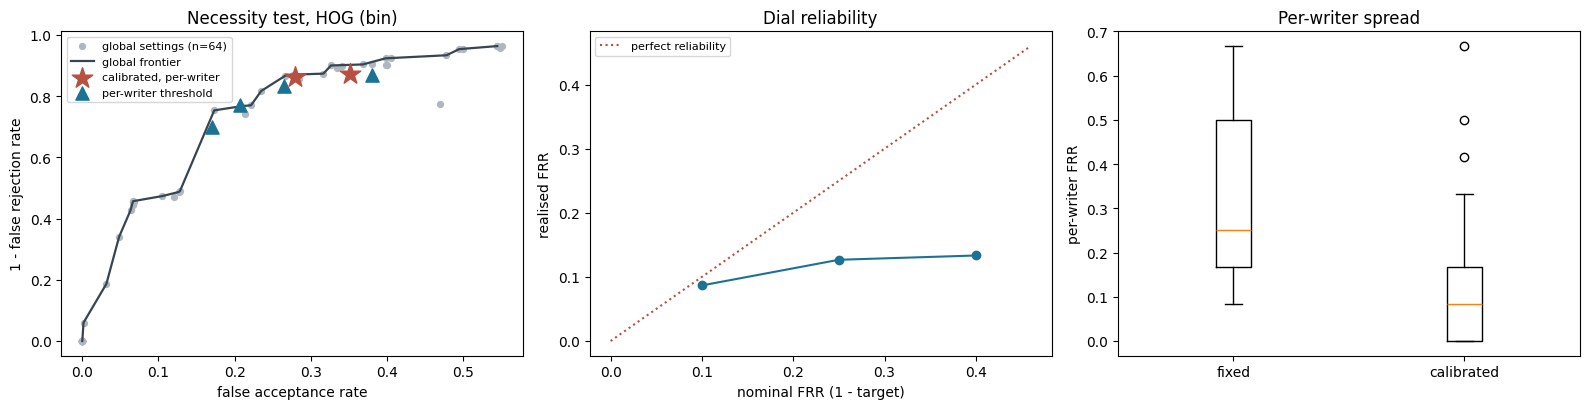

[timer] 8 reliability: 118.0s   (total 899.6s)


In [18]:
REL_TARGETS = (0.60, 0.75, 0.90)
rel = []
for t in REL_TARGETS:
    cal = {}
    for wid in DEV:
        s = DS[PRIMARY][wid]; cs, _ = cohort_pool_sigs(PRIMARY[0], PRIMARY[1], wid)
        cal[wid] = calibrate_writer(s["W"], s["D"], s["idx"], cs, "target", target=t,
                                    desc_fn=DESC_FOR[PRIMARY[0]])
    params = {w: {"nu":cal[w]["nu"], "gamma":cal[w]["gamma"]} for w in DEV}
    df, ov = evaluate(PRIMARY, params, f"target={t}")
    rel.append({"target":t, "nominal_FRR":1-t, "realised_FRR":ov["FRR"],
                "error":ov["FRR"]-(1-t), "FAR":ov["FAR"], "BalAcc":ov["BalAcc"],
                "FRR_sd":float(df.FRR.std()), "FRR_iqr":float(df.FRR.quantile(.75)-df.FRR.quantile(.25))})
    print(f"  target {t:.2f}  nominal FRR {1-t:.2f}  realised {ov['FRR']:.4f}  "
          f"error {ov['FRR']-(1-t):+.4f}  per-writer SD {df.FRR.std():.4f}", flush=True)
REL = pd.DataFrame(rel); REL.to_csv(OUT_DIR/"dial_reliability.csv", index=False)

bdf = base_df[PRIMARY].set_index("Writer")
cdf_m = pd.read_csv(OUT_DIR/f"per_writer_{PRIMARY[0]}_{PRIMARY[1]}_margin.csv").set_index("Writer")
print("\n" + "="*96); print("PER-WRITER FRR SPREAD, fixed vs calibrated (primary arm)"); print("="*96)
print(f"  fixed      mean {bdf.FRR.mean():.4f}  SD {bdf.FRR.std():.4f}  "
      f"IQR {bdf.FRR.quantile(.75)-bdf.FRR.quantile(.25):.4f}  range "
      f"[{bdf.FRR.min():.4f}, {bdf.FRR.max():.4f}]")
print(f"  calibrated mean {cdf_m.FRR.mean():.4f}  SD {cdf_m.FRR.std():.4f}  "
      f"IQR {cdf_m.FRR.quantile(.75)-cdf_m.FRR.quantile(.25):.4f}  range "
      f"[{cdf_m.FRR.min():.4f}, {cdf_m.FRR.max():.4f}]")
print(f"\n  A mechanism claiming per-writer control should narrow this spread.")
print(f"  SD change: {cdf_m.FRR.std()-bdf.FRR.std():+.4f}")
print(f"  mean |realised - nominal| FRR across targets: {REL.error.abs().mean():.4f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
g = GLOBAL[PRIMARY]; fr = pareto_front(g)
ax[0].scatter(g.FAR, 1-g.FRR, s=18, c="#B0B7BF", label=f"global settings (n={len(g)})")
ax[0].plot(fr.FAR, 1-fr.FRR, "-", color="#36454F", lw=1.6, label="global frontier")
cal_pts = RES[(RES.Arm==f"{PRIMARY[0]}-{PRIMARY[1]}")&(RES.Method=="calibrated")]
ax[0].scatter(cal_pts.FAR, 1-cal_pts.FRR, marker="*", s=240, color="#B85042",
              zorder=5, label="calibrated, per-writer")
thr_pts = RES[(RES.Arm==f"{PRIMARY[0]}-{PRIMARY[1]}")&(RES.Method=="per-writer threshold")]
ax[0].scatter(thr_pts.FAR, 1-thr_pts.FRR, marker="^", s=90, color="#1C7293",
              zorder=4, label="per-writer threshold")
ax[0].set_xlabel("false acceptance rate"); ax[0].set_ylabel("1 - false rejection rate")
ax[0].set_title(f"Necessity test, {PRIMARY[0]} ({PRIMARY[1]})"); ax[0].legend(fontsize=8)
ax[1].plot(REL.nominal_FRR, REL.realised_FRR, "o-", color="#1C7293")
lim = [0, max(REL.nominal_FRR.max(), REL.realised_FRR.max())*1.15]
ax[1].plot(lim, lim, ":", color="#B85042", label="perfect reliability")
ax[1].set_xlabel("nominal FRR (1 - target)"); ax[1].set_ylabel("realised FRR")
ax[1].set_title("Dial reliability"); ax[1].legend(fontsize=8)
ax[2].boxplot([bdf.FRR.values, cdf_m.FRR.values])
ax[2].set_xticks([1,2]); ax[2].set_xticklabels(["fixed","calibrated"])
ax[2].set_ylabel("per-writer FRR"); ax[2].set_title("Per-writer spread")
plt.tight_layout(); plt.savefig(OUT_DIR/"necessity_and_reliability.png", dpi=130); plt.show()
mark("8 reliability")

## 10. Summary and runtime

In [19]:
print("="*132); print("SUMMARY -- 25 development writers"); print("="*132)
print(RES[SHOW].round(4).to_string(index=False))

print("\n  Controls (fixed baseline AUC):")
for c in CONDITIONS:
    for r in CONTROL_REPS:
        print(f"    {r}-{c}: {ctrl_auc[(r,c)]:.4f}")
print("\n  Representation margins over controls, 95% bootstrap intervals:")
for _, r in CI.iterrows():
    print(f"    {r.Rep}-{r.Condition} vs {r.Control:3s}: {r.margin:+.4f} "
          f"[{r.ci_lo:+.4f}, {r.ci_hi:+.4f}]{'  spans zero' if r.spans_zero else ''}")

print(f"\n  Necessity: "
      f"{int(RES[RES.Method=='calibrated'].dominated_by_global.sum())} of "
      f"{int((RES.Method=='calibrated').sum())} calibrated configurations dominated by a global setting")
print(f"  Kernel degeneracy: {int(CD.degenerate_writers.sum())} writer-runs flagged")
print(f"  Dial reliability: mean |realised - nominal| FRR = {REL.error.abs().mean():.4f}")
print(f"  Per-writer FRR spread, fixed SD {bdf.FRR.std():.4f} -> calibrated SD {cdf_m.FRR.std():.4f}")
print(f"\n  Confirmation writers ({len(CONFIRM)}) remain unevaluated.")

total = time.time()-NB_T0; h, rem = divmod(total, 3600); m_, s_ = divmod(rem, 60)
print("\n" + "="*70); print("RUNTIME"); print("="*70)
print(f"  Google Colaboratory, High-RAM, Python {sys.version.split()[0]}, CPU")
print(f"  OneClassSVM is CPU-only; no GPU or TPU backend exists for this estimator.")
print("-"*70)
for k, v in SECTION_TIMES.items():
    if k == "_last": continue
    print(f"  {k:28s} {v:8.1f}s  ({v/60:5.2f} min)")
print("-"*70)
print(f"  TOTAL {int(h)}h {int(m_)}m {int(s_)}s  ({total/60:.1f} min)")
pd.DataFrame([{"section":k,"seconds":v} for k,v in SECTION_TIMES.items() if k!="_last"]) \
  .to_csv(OUT_DIR/"v7_runtime.csv", index=False)
print(f"\n  Artifacts: {OUT_DIR}")
for fp in sorted(OUT_DIR.glob("*")): print("   ", fp.name)

SUMMARY -- 25 development writers
     Arm               Method              detail    FRR    FAR  Accuracy     F1    AUC  BalAcc  FRR_matched_FAR  dominated_by_global
 HOG-bin          best global nu=0.15, gamma=0.01 0.1333 0.2667    0.7778 0.7519 0.8403  0.8000           0.1233                False
 HOG-bin per-writer threshold              q=0.05 0.1300 0.3800    0.7033 0.6925 0.8501  0.7450              NaN                 True
 HOG-bin per-writer threshold              q=0.10 0.1667 0.2650    0.7678 0.7310 0.8501  0.7842              NaN                False
 HOG-bin per-writer threshold              q=0.20 0.2300 0.2067    0.7856 0.7234 0.8501  0.7817              NaN                False
 HOG-bin per-writer threshold              q=0.30 0.3000 0.1700    0.7867 0.6997 0.8501  0.7650              NaN                False
 HOG-bin           calibrated              target 0.1267 0.3517    0.7233 0.7031 0.8336  0.7608           0.1467                 True
 HOG-bin           calibrate